### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [2]:
data = pd.read_csv('data/coupons.csv')

In [3]:
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [4]:
missing = data.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

car                     12576
CoffeeHouse               217
Restaurant20To50          189
CarryAway                 151
RestaurantLessThan20      130
Bar                       107
dtype: int64

3. Decide what to do about your missing data -- drop, replace, other...

In [37]:
data['CarryAway'] = data['CarryAway'].fillna(0)
data['CoffeeHouse'] = data['CoffeeHouse'].fillna(0)
data['Restaurant20To50'] = data['Restaurant20To50'].fillna(0)
data['RestaurantLessThan20'] = data['RestaurantLessThan20'].fillna(0)
data['Bar'] = data['Bar'].fillna(0)
data = data.drop(columns=['car'])
data

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y,Coffeehouse
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,0,4~8,1~3,1,0,0,0,1,1,never
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,0,4~8,1~3,1,0,0,0,1,0,never
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,0,4~8,1~3,1,1,0,0,1,1,never
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,0,4~8,1~3,1,1,0,0,1,0,never
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,0,4~8,1~3,1,1,0,0,1,0,never
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12679,Home,Partner,Rainy,55,6PM,Carry out & Take away,1d,Male,26,Single,...,1~3,4~8,1~3,1,0,0,1,0,1,never
12680,Work,Alone,Rainy,55,7AM,Carry out & Take away,1d,Male,26,Single,...,1~3,4~8,1~3,1,0,0,0,1,1,never
12681,Work,Alone,Snowy,30,7AM,Coffee House,1d,Male,26,Single,...,1~3,4~8,1~3,1,0,0,1,0,0,never
12682,Work,Alone,Snowy,30,7AM,Bar,1d,Male,26,Single,...,1~3,4~8,1~3,1,1,1,0,1,0,never


4. What proportion of the total observations chose to accept the coupon?



In [8]:
proportion = data['Y'].value_counts(normalize=True) * 100
print(proportion)

Y
1    56.843267
0    43.156733
Name: proportion, dtype: float64


5. Use a bar plot to visualize the `coupon` column.

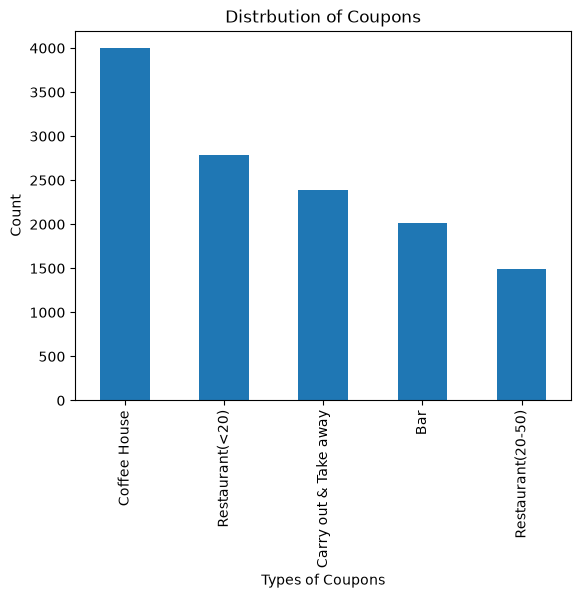

In [14]:
data['coupon'].value_counts().plot(kind='bar')
plt.xlabel('Types of Coupons')
plt.ylabel('Count')
plt.title('Distrbution of Coupons')
plt.show()

6. Use a histogram to visualize the temperature column.

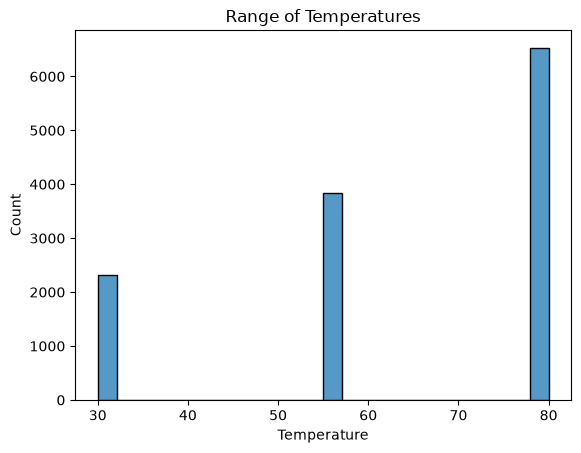

In [13]:
sns.histplot(data['temperature'])
plt.xlabel('Temperature')
plt.ylabel('Count')
plt.title('Range of Temperatures')
plt.show()

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [59]:
bar_only = ['Bar']
bar = data[data['coupon'].isin(bar_only)]
bar

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
9,No Urgent Place,Kid(s),Sunny,80,10AM,Bar,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
13,Home,Alone,Sunny,55,6PM,Bar,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,1,0,1
17,Work,Alone,Sunny,55,7AM,Bar,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,1,0,1,0
24,No Urgent Place,Friend(s),Sunny,80,10AM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,0,1,1
35,Home,Alone,Sunny,55,6PM,Bar,1d,Male,21,Single,...,less1,4~8,4~8,less1,1,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12663,No Urgent Place,Friend(s),Sunny,80,10PM,Bar,1d,Male,26,Single,...,never,1~3,4~8,1~3,1,1,0,0,1,0
12664,No Urgent Place,Friend(s),Sunny,55,10PM,Bar,2h,Male,26,Single,...,never,1~3,4~8,1~3,1,1,0,0,1,0
12667,No Urgent Place,Alone,Rainy,55,10AM,Bar,1d,Male,26,Single,...,never,1~3,4~8,1~3,1,1,0,0,1,0
12670,No Urgent Place,Partner,Rainy,55,6PM,Bar,2h,Male,26,Single,...,never,1~3,4~8,1~3,1,1,0,0,1,0


2. What proportion of bar coupons were accepted?


In [23]:
bar_acc = bar['Y'].value_counts(normalize=True) * 100
print(bar_acc)

Y
0    58.998513
1    41.001487
Name: proportion, dtype: float64


3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [60]:
acceptance_3_or_less = data[data["Bar"].isin(["less1", "1~3"])]["Y"].mean()
acceptance_more_than_3 = data[data["Bar"].isin(["4~8", "gt8"])]["Y"].mean()
print("Acceptance rate for 3 or fewer times:",
      acceptance_3_or_less * 100, "%")
print("Acceptance rate for more than 3 times:",
      acceptance_more_than_3 * 100, "%")

Acceptance rate for 3 or fewer times: 58.79093198992443 %
Acceptance rate for more than 3 times: 62.24561403508771 %


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [4]:
condition = (
    data["Bar"].isin(["1~3", "4~8", "gt8"]) &
    data["age"].isin(["26", "31", "36", "41", "46", "50plus"])
)
acc_1 = data.loc[condition, "Y"].mean()
acc_others = data.loc[~condition, "Y"].mean()
print("Acceptance rate for group:", acc_1 * 100, "%")
print("Acceptance rate for all others:", acc_others * 100, "%")

Acceptance rate for group: 62.15340295282679 %
Acceptance rate for all others: 55.35479963662057 %


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [63]:
filtered = data[
    (data['Bar'].isin(['1~3', '4~8', 'gt8'])) &
    (data['passanger'] != 'Kid(s)') &
    (data['occupation'] != 'Farming Fishing & Forestry')
]
acceptance_rate = filtered['Y'].mean()
print(f"Acceptance rate: {acceptance_rate * 100:.2f}%")

Acceptance rate: 62.31%


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [64]:
conditiona = (
    data['Bar'].isin(['1~3', '4~8', 'gt8']) &
    (data['passanger'] != 'Kid(s)') &
    (data['maritalStatus'] != 'Widowed')
)
conditionb = (
    data['Bar'].isin(['1~3', '4~8', 'gt8']) &
    data['age'].isin(['below21', '21', '26'])
)
conditionc = (
    data['RestaurantLessThan20'].isin(['4~8', 'gt8']) &
    data['income'].isin([
        'Less than $12500',
        '$12500 - $24999',
        '$25000 - $37499',
        '$37500 - $49999'
    ])
)
rate1 = data.loc[conditiona, 'Y'].mean()
rate2 = data.loc[conditionb, 'Y'].mean()
rate3 = data.loc[conditionc, 'Y'].mean()
print(f"Condition A: {rate1 * 100:.2f}%")
print(f"Condition B: {rate2 * 100:.2f}%")
print(f"Condition C: {rate3 * 100:.2f}%")

Condition A: 62.31%
Condition B: 62.81%
Condition C: 60.07%


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

In [ ]:
# Based on these results, I hypothesize that drivers who go to bars more frequently are more likely to accept bar coupons, 
# particularly those who visit bars more than once a month. The overall acceptance rate was approximately 41%, while drivers who 
# went to bars more than once a month and were over 25 had an acceptance rate of about 62.15%. This suggests that frequent bar 
# visitors may be more interested in accepting these coupons because they already participate in activities involving bars. 
# Also, the acceptance rates for the three groups in Question 6 were all relatively similar, ranging from 60.07% to 62.81%, which 
# suggests that factors such as age, passenger type, marital status, occupation, and dining habits may also play a role in coupon 
# acceptance. The results suggest that drivers who regularly visit bars are more likely to accept bar coupons, although 
# these characteristics alone do not necessarily explain why someone accepts a coupon.

### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

In [41]:
# Create a new DataFrame that contains just the coffeehouse coupons.
CoffeeHouse_only = ['Coffee House']
CoffeeHouse = data[data['coupon'].isin(CoffeeHouse_only)]
CoffeeHouse

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
12,No Urgent Place,Kid(s),Sunny,55,6PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
15,Home,Alone,Sunny,80,6PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12656,Home,Alone,Snowy,30,10PM,Coffee House,2h,Male,31,Married partner,...,never,4~8,gt8,less1,1,1,0,0,1,0
12659,Work,Alone,Snowy,30,7AM,Coffee House,1d,Male,31,Married partner,...,never,4~8,gt8,less1,1,0,0,1,0,0
12674,Home,Alone,Rainy,55,10PM,Coffee House,2h,Male,26,Single,...,never,1~3,4~8,1~3,1,0,0,1,0,0
12675,Home,Alone,Snowy,30,10PM,Coffee House,2h,Male,26,Single,...,never,1~3,4~8,1~3,1,1,0,0,1,0


In [29]:
# What proportion of coffeehouse coupons were accepted?
CoffeeHouse_acc = CoffeeHouse['Y'].value_counts(normalize=True) * 100
print(CoffeeHouse_acc)

Y
0    50.075075
1    49.924925
Name: proportion, dtype: float64


In [65]:
# Compare the acceptance rate between those who went to a coffeehouse 3 or fewer times a month to those who went more.
acceptance_3c_or_less = data[data["CoffeeHouse"].isin(["less1", "1~3"])]["Y"].mean()
acceptance_morec_than_3 = data[data["CoffeeHouse"].isin(["4~8", "gt8"])]["Y"].mean()
print("Acceptance rate for 3 or fewer times:",
      acceptance_3c_or_less * 100, "%")
print("Acceptance rate for more than 3 times:",
      acceptance_morec_than_3 * 100, "%")

Acceptance rate for 3 or fewer times: 59.90922844175491 %
Acceptance rate for more than 3 times: 61.416234887737474 %


In [66]:
# Compare the acceptance rate between drivers who go to a coffeehouse more than once a month and are over the age of 25 to the all others. 
# Is there a difference?
condition = (
    data["CoffeeHouse"].isin(["1~3", "4~8", "gt8"]) &
    data["age"].isin(["26", "31", "36", "41", "46", "50plus"])
)
acc_1 = data.loc[condition, "Y"].mean()
acc_others = data.loc[~condition, "Y"].mean()
print("Acceptance rate for group:", acc_1 * 100, "%")
print("Acceptance rate for all others:", acc_others * 100, "%")

Acceptance rate for group: 62.554660529344076 %
Acceptance rate for all others: 53.86737018827198 %


In [5]:
# Use the same process to compare the acceptance rate between drivers who go to coffeehouse more than once a 
# month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.
filtered = data[
    (data['CoffeeHouse'].isin(['1~3', '4~8', 'gt8'])) &
    (data['passanger'] != 'Kid(s)') &
    (data['occupation'] != 'Farming Fishing & Forestry')
]
acceptance_rate = filtered['Y'].mean()
print(f"Acceptance rate: {acceptance_rate * 100:.2f}%")

Acceptance rate: 64.20%


In [6]:
# Compare the acceptance rates between those drivers who:
# go to coffeehouses more than once a month, had passengers that were not a kid, and were not widowed OR
# go to coffeehouses more than once a month and are under the age of 30 OR
# go to coffeehouses more than 4 times a month and income is less than 50K.
conditiona = (
    data['CoffeeHouse'].isin(['1~3', '4~8', 'gt8']) &
    (data['passanger'] != 'Kid(s)') &
    (data['maritalStatus'] != 'Widowed')
)
conditionb = (
    data['CoffeeHouse'].isin(['1~3', '4~8', 'gt8']) &
    data['age'].isin(['below21', '21', '26'])
)
conditionc = (
    data['RestaurantLessThan20'].isin(['4~8', 'gt8']) &
    data['income'].isin([
        'Less than $12500',
        '$12500 - $24999',
        '$25000 - $37499',
        '$37500 - $49999'
    ])
)
rate1 = data.loc[conditiona, 'Y'].mean()
rate2 = data.loc[conditionb, 'Y'].mean()
rate3 = data.loc[conditionc, 'Y'].mean()
print(f"Condition A: {rate1 * 100:.2f}%")
print(f"Condition B: {rate2 * 100:.2f}%")
print(f"Condition C: {rate3 * 100:.2f}%")

Condition A: 64.20%
Condition B: 67.08%
Condition C: 60.07%


In [ ]:
# Based on these observations, drivers who accepted coffeehouse coupons appear to be more likely to visit coffeehouses regularly, 
# particularly those who visit more than once a month. Acceptance was also higher among drivers over the age of 25 who visited coffeehouses 
# more than once a month (62.55%) compared with all other drivers (53.87%). Additionally, drivers under 30 who visited coffeehouses more 
# than once a month had a relatively high acceptance rate of 67.08%. Other characteristics associated with higher acceptance included 
# having a non-child passenger and not being widowed, as well as having an occupation outside farming, fishing, or forestry. These results 
# suggest that coffeehouse visitation frequency is an important indicator of coupon acceptance, while age, passenger type, marital status, 
# and occupation may also help identify drivers more likely to accept coffeehouse coupons.